# Efficiency on the Dalitz Plot

Let's try to use SBI to infer the efficiency on the Dalitz plot.
We will start with a simple example, in which the efficiency is due to an effect on the diagonal.

In [2]:
from context import sbitest
from sbitest.dalitz import DalitzPhaseSpace

In [3]:
phsp = DalitzPhaseSpace(ma=0.5, mb=0.2, mc=0.2, md=2.0)

In [4]:
gen_sample = phsp.uniform_sample(10_000)

Define an efficiency function based on the third variable of the sample with a 2nd order polinomial

In [9]:
import matplotlib.pyplot as plt
import numpy as np

In [27]:
def efficiency(x, p0, p1, p2):
    return p0 + p1 * x + p2 * x * x

In [28]:
a = 0.5
c = (a - 1.) / phsp.maxac / phsp.maxac
b = -2 * c *phsp.maxac

Text(0, 0.5, 'efficiency')

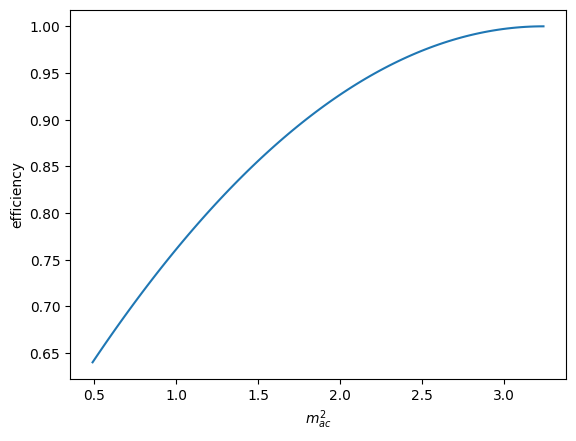

In [31]:
X = np.linspace(phsp.minac, phsp.maxac, 100)
fig, ax = plt.subplots()
ax.plot(X, efficiency(X, p0 = a, p1=b, p2=c))
ax.set_xlabel(r"$m^2_{ac}$")
ax.set_ylabel("efficiency")

Now define a simulator to implement the efficiency function in the Dalitz phase space

In [32]:
import torch

_ = torch.manual_seed(0)

def simulate(parameters, n_events=2_000, chunk_size=20_000):
    """Generate events with accept-reject using efficiency(m2ac).
    
    parameters: tensor/array-like with [p0, p1, p2]
    returns: torch tensor of shape (n_events, 2) with [m2ab, m2bc]
    """
    p0, p1, p2 = [float(x) for x in torch.as_tensor(parameters).detach().cpu().numpy()]

    accepted = []
    n_kept = 0

    while n_kept < n_events:
        # Draw candidates uniformly in phase space + auxiliary uniform random U in [0, 1].
        candidates = phsp.uniform_sample(chunk_size, maximum=1.0)
        m2ac = phsp.m2ac(candidates)

        # Efficiency as acceptance probability, clipped to [0, 1].
        acc_prob = np.clip(efficiency(m2ac, p0, p1, p2), 0.0, 1.0)
        keep = candidates[:, 2] < acc_prob

        kept = candidates[keep, :2]
        if kept.shape[0] > 0:
            accepted.append(kept)
            n_kept += kept.shape[0]

    sample = np.concatenate(accepted, axis=0)[:n_events]
    return torch.as_tensor(sample, dtype=torch.float32)

In [40]:
rec_sample = simulate([a, b, c], n_events=100_000)

Text(0, 0.5, '$m^2_{bc}$')

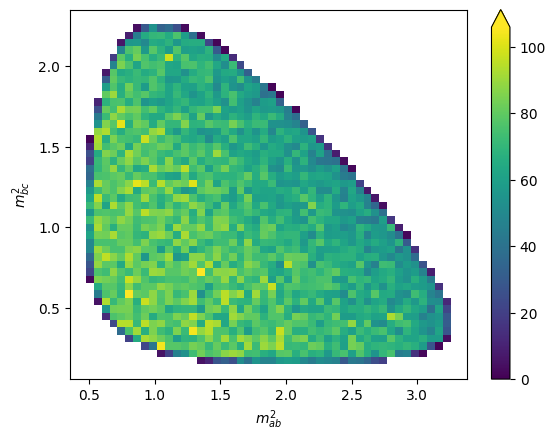

In [41]:
from sbitest.plotting import plot_dalitz
fig, ax = plt.subplots()
plot_dalitz(phsp.m2ab(rec_sample), phsp.m2bc(rec_sample), ax=ax, bins=50)
ax.set_xlabel(r"$m^2_{ab}$")
ax.set_ylabel(r"$m^2_{bc}$")